In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import linregress

RESULTS_DIR = Path('results')
GRAPHS_DIR = Path('graphs')
GRAPHS_DIR.mkdir(exist_ok=True)


In [7]:
df = pd.read_csv(RESULTS_DIR / 'ejercicio1_datos.csv')
n_bytes = df['bytes'].to_numpy()
tiempos = df['tiempo_s'].to_numpy()
df

,bytes,tiempo_s
0,1,0.000027
1,1024,0.000035
2,16384,0.000062
3,65536,0.000141
4,262144,0.000364
5,1048576,0.001049
6,16777216,0.014453
7,67108864,0.057785
8,134217728,0.115350
9,268435456,0.230340


In [8]:
pendiente, ordenada, r_val, p_val, std_err = linregress(n_bytes, tiempos)

latencia_s = ordenada
ancho_banda_Bps = 1.0 / pendiente

latencia_us = latencia_s * 1e6
ancho_banda_MBs = ancho_banda_Bps / (1024.0 * 1024.0)
ancho_banda_Mbps = (ancho_banda_Bps * 8.0) / 1e6

print(f'Latencia (l): {latencia_us:.2f} us')
print(f'Ancho de banda (b): {ancho_banda_Mbps:.2f} Mb/s ({ancho_banda_MBs:.2f} MB/s)')
print(f'R^2: {r_val**2:.6f}')

Latencia (l): 95.84 us
Ancho de banda (b): 9324.02 Mb/s (1111.51 MB/s)
R^2: 0.999999


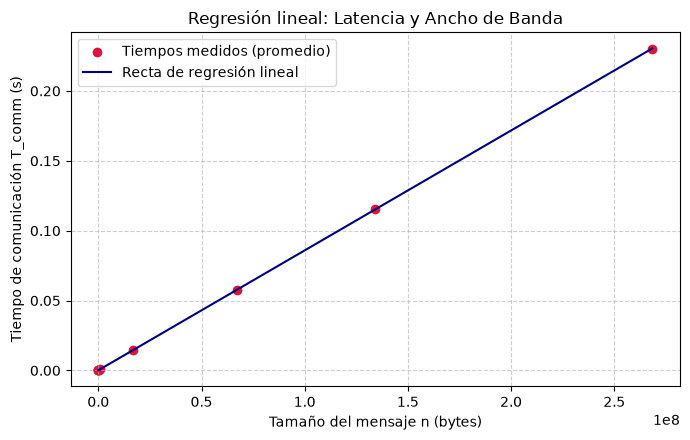

In [9]:
plt.figure(figsize=(7, 4.5))
plt.scatter(n_bytes, tiempos, color='crimson', label='Tiempos medidos (promedio)')
plt.plot(n_bytes, ordenada + pendiente * n_bytes, color='navy', label='Recta de regresión lineal')
plt.xlabel('Tamaño del mensaje n (bytes)')
plt.ylabel('Tiempo de comunicación T_comm (s)')
plt.title('Regresión lineal: Latencia y Ancho de Banda')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(GRAPHS_DIR / 'e1_regresion_lineal.png', dpi=300, bbox_inches='tight')
plt.show()